# Queueing Theory

Moreno Marzolla

Last modified on 2026-11-20

---

In [2]:
import numpy as np
import matplotlib.pyplot as plt

## Computation of visit counts

Let us define a function `qncsvisits(P, r)` that computes the visit counts $\mathbf{V} = (V_0, \ldots, V_{K-1})$ of a closed, single-class network with $K$ service centers, given routing probabilities $\mathbf{P} = [P_{ij}]$ and reference station $r$ (default 0). The visit counts $\mathbf{V}$ satisfy the following system of linear equations:

$$
\begin{cases}
\mathbf{V} &= \mathbf{V} \mathbf{P} \\
V_r &= 1
\end{cases}
$$

that can be rewritten as:

$$
\begin{cases}
\mathbf{V}(\mathbf{I} - \mathbf{P}) &= \mathbf{0} \\
V_r &= 1
\end{cases}
$$


In [3]:
def qncsvisits(P, r=0):
    """
    Compute visit ratios for a closed single-class queueing network.
    Semi-automatic translation of function qncsvisits() from the Octave Queueing package.

    Parameters
    ----------
    P : array_like, shape (K, K)
        Routing probability matrix.
    r : int, optional
        Reference station index (0-based). The visit count of this
        station is normalized to 1.

    Returns
    -------
    V : ndarray, shape (K,)
        Visit ratios.
    """
    P = np.asarray(P, dtype=float)
    K = P.shape[0]

    A = np.eye(K) - P # A = (I - P)
    b = np.zeros(K)

    # set the normalization condition 
    A[:, r] = 0.0
    A[r, r] = 1.0
    b[r] = 1.0

    # Octave: V = b / A
    # equivalent to solving V A = b
    V = np.linalg.solve(A.T, b)
    # clamp negative values to zero; numerical errors in np.linalg.solve
    # can sometimes produce small negative visit counts.
    return np.maximum(0.0, V)

Let us test the function using the simple closed network shown during the lectures.

In [4]:
# Example from the slides
P = np.array([[0.0, 0.2, 0.8],
              [1.0, 0.0, 0.0],
              [1.0, 0.0, 0.0]])

# using 0 as the reference station
V = qncsvisits(P, 0)
print(V)
assert np.allclose(V, [1, 0.2, 0.8])

[1.  0.2 0.8]


In [5]:
# using 1 as the reference station
V = qncsvisits(P, 1)
print(V)
assert np.allclose(V, [5, 1, 4])

[5. 1. 4.]


The definition of visit counts for open networks is slightly different. Let $\lambda_i$ the arrival rate at center $i$. Let $P_{-1, i}$ be the probability that an external arrival goes to center $i$:

$$
P_{-1, i} = \frac{\lambda_i}{\sum_i \lambda_i}
$$

Then, the visit counts $V_i$ satisfy the following constraints:

$$
V_i = P_{-1, i} + \sum_j V_j P_{j,i} \qquad i = 0, \ldots, K-1
$$

that might be rewritten in vector form as:

$$
\mathbf{V} = \mathbf{P}_{-1} + \mathbf{V} \mathbf{P}
$$

where $\mathbf{P}_{-1} = (P_{-1, 0}, \ldots, P_{-1, K-1})$

In [6]:
def qnosvisits(P, lam):
    """
    Compute visit ratios for an open single-class queueing network.
    Semi-automatic translation of function qnosvisits() from the Octave Queueing package.
    
    Parameters
    ----------
    P : array_like, shape (K, K)
        Routing probability matrix.
    lam : array_like, shape (K,)
        External arrival rates at each service center.

    Returns
    -------
    V : ndarray, shape (K,)
        Visit ratios.
    """
    P = np.asarray(P, dtype=float)
    
    K = P.shape[0]

    A = np.eye(K) - P
    b = lam / np.sum(lam)

    # Octave: V = b / A
    # Equivalent to solving V A = b
    V = np.linalg.solve(A.T, b)

    # Remove tiny negative values due to numerical roundoff
    V = np.maximum(0.0, V)

    return V

In [7]:
# Example from the slides
P = np.array([[0.0, 0.2, 0.8],
              [1.0, 0.0, 0.0],
              [0.0, 0.0, 0.0]])
lam = np.array([0.5, 0, 0])
V = qnosvisits(P, lam)
print(V)
assert np.allclose(V, [1.25, 0.25, 1.0])

[1.25 0.25 1.  ]


## Analysis of open networks

We now implement an algorithm for analyzing open queueing networks that consist of $K$ centers of type M/M/1 or M/M/$\infty$. There is a single class of requests. The user must provide the following input parameters:

- Global arrival rate $\lambda$;
- Visit counts $V_k$;
- Mean service times $S_k$;
- Whether center $k$ is a queueing (M/M/1) or a delay center (M/M/$\infty$).

Function `qn_open()` returns the following measures for each service center $k$:

- Utilizations $U_k$;
- Response times $R_k$;
- Mean number of requests $Q_k$;
- Throughputs $X_k$.

from which it is possible to derive aggregate metrics:

- System throughput $X = \lambda$, provided that the system is stable;
- System response time $R = \sum_k V_k R_k$;
- Average number of requests in the system $Q = \sum_k Q_k$.

In [8]:
def qn_open(lam, V, S, delay):
    """
    Analyze an open product-form queueing network consisting of
    M/M/1 queueing centers and infinite-server delay centers.
    This is a semi-automatic translation of function qncsopen()
    from the Octave Queueing package.

    Parameters
    ----------
    lam : float
        System arrival rate.
    V : array_like, shape (K,)
        Visit ratios.
    S : array_like, shape (K,)
        Mean service times.
    delay : array_like of bool, shape (K,)
        delay[k] is True if node k is an infinite-server
        delay center, False if it is an M/M/1 queue.

    Returns
    -------
    U : ndarray, shape (K,)
        Utilizations.
    R : ndarray, shape (K,)
        Mean response times.
    Q : ndarray, shape (K,)
        Mean number of jobs.
    X : ndarray, shape (K,)
        Throughputs.
    """
    V = np.asarray(V, dtype=float)
    S = np.asarray(S, dtype=float)
    delay = np.asarray(delay, dtype=bool)

    D = V * S          # Service demands
    U = lam * D        # Utilizations

    R = np.zeros_like(S, dtype=float)
    Q = np.zeros_like(S, dtype=float)

    # Delay centers (infinite-server)
    R[delay] = S[delay]
    Q[delay] = U[delay]

    # Queueing centers (M/M/1)
    q = ~delay
    R[q] = S[q] / (1.0 - U[q])
    Q[q] = U[q] / (1.0 - U[q])
    
    X = lam * V
    
    return U, R, Q, X

Let us try the following network. The parameters are given below.

<center>
<img src="open-network-analysis.svg" width="400px"/>
</center>

In [9]:
V = np.array([121, 70, 50]);
S = np.array([0.005, 0.030, 0.027])
delay = np.array([False, False, False]) # all service centers are queueing centers
lam = 0.3 # aggregate arrival rate

U, R, Q, X = qn_open(lam, V, S, delay)

print("Utilizations:       ", U)
print("Response times:     ", R)
print("Mean n. of requests:", Q)
print("Throughputs:        ", X)
Rsys = np.dot(V, R)
print("System response time:", Rsys)
Qsys = np.sum(Q)
print("System mean n. of requests:", Qsys)

Utilizations:        [0.1815 0.63   0.405 ]
Response times:      [0.00610874 0.08108108 0.04537815]
Mean n. of requests: [0.2217471  1.7027027  0.68067227]
Throughputs:         [36.3 21.  15. ]
System response time: 8.683740233203023
System mean n. of requests: 2.605122069960907


What is the maximum throughput that the system can sustain? From the utilization law we know that 

$$
U_k = X_k S_k \qquad \text{(Utilization Law)}
$$

and the forced flow law states that

$$
X_k = V_k X  = V_k \lambda \qquad \text{(Forced Flow Law)}
$$

provided that the system is stable ($X = \lambda$).
Combining the two equations above, and recalling the definition of service demands $D_k = V_k S_k$, we can write

$$
U_k = \lambda V_k S_k = \lambda D_k \qquad k = 0, \ldots, K-1
$$

and since the utilizations must be less than 1, we have:

$$
\lambda < \lambda_\text{max} = \frac{1}{D_\text{max}}
$$

where $D_\text{max} = \max\{D_k\}$ is the maximum service demand. This shows that **the system bottleneck is the device with maximum service demand**.

Going back to our example, the maximum arrival rate that the system can sustain is

In [10]:
lam_max = 1 / np.max(V*S)
print(lam_max)

0.47619047619047616


We can show that the system response time goes to infinity as the arrival rate approaches the saturation value $\lambda_\text{max}$.

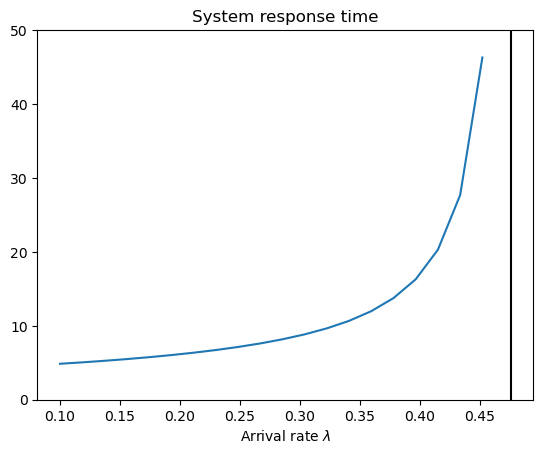

In [11]:
lams = np.linspace(0.1, 0.95*lam_max, 20)
Rsys = np.zeros_like(lams, dtype=float)
for i,_ in enumerate(lams):
    _, R, _, _ = qn_open(lams[i], V, S, delay)
    Rsys[i] = np.dot(R, V)
plt.plot(lams, Rsys)
plt.xlabel(f"Arrival rate $\\lambda$")
plt.title(f"System response time")
plt.axvline(lam_max, color='black')
plt.ylim([0, 50])
plt.show();

## Analysis of closed networks

The Mean Value Analysis (MVA) algorithm can be used to analyze closed networks. Our implementation handles networks made of $K$ service centers of type M/M/1 or M/M/$\infty$. There is a single class of customers of size $N$. Requests spend time $Z$ ("think time") outside the system.

<center>
<img src="closed-system-model.svg" width="400px"/>    
</center>

The model's input parameters are:

- Number of requests $N$;
- Visit counts $V_k$;
- Mean service times $S_k$;
- External delay ("think time") $Z$;
- Whether center $k$ is a queueing (M/M/1) or a delay center (M/M/$\infty$).

Function `mva()` returns the following performance measures for each service center $k$:

- Utilizations $U_k$;
- Response times $R_k$;
- Mean number of requests $Q_k$;
- Throughputs $X_k$.

from which it is possible to derive aggregate metrics:

- System throughput $X = \frac{N}{Z + R}$ (Little's law);
- System response time $R = \sum_k V_k R_k$;
- Average number of requests $Q$ in the system (not in the external delay); can be computed in several ways, all equivalent:
  - $Q = \sum_k Q_k$, or 
  - $Q = N - XZ$, or 
  - $Q = XR$.

In [12]:
def mva(N, V, S, Z, delay):
    """
    Mean Value Analysis (MVA) for a closed single-class queueing network
    with M/M/1 queues and infinite-server delay centers. This is a semi-automatic
    translation of function qncsmva() from the Octave Queueing Package.

    Parameters
    ----------
    N : int
        Total number of customers/jobs in the system.
    V : array_like, shape (K,)
        Visit counts.
    S : array_like, shape (K,)
        Mean service times.
    Z : float
        External delay (think time).
    delay : array_like of bool, shape (K,)
        delay[k] is True iff service center k is an infinite-server
        delay center.

    Returns
    -------
    U : ndarray, shape (K,)
        Utilizations.
    R : ndarray, shape (K,)
        Mean response times.
    Q : ndarray, shape (K,)
        Mean queue lengths.
    X : ndarray, shape (K,)
        Throughputs.
    """
    N = int(N)
    V = np.asarray(V, dtype=float)
    S = np.asarray(S, dtype=float)
    delay = np.asarray(delay, dtype=bool)

    K = len(S)
    Q = np.zeros(K, dtype=float)
    R = np.zeros(K, dtype=float)
    D = V * S # service demands
    X = 0.0 # system throughput

    # for each population 1, 2, ... N
    for n in range(1, N + 1):
        # Residence times
        R[delay] = S[delay]
        R[~delay] = S[~delay] * (1.0 + Q[~delay])

        # System response time
        R_tot = np.dot(V, R)

        # System throughput
        X = n / (Z + R_tot)

        # Mean number of jobs at each center
        Q = X * V * R

    # Utilizations
    U = X * D

    return U, R, Q, X*V

Let us analyze the following closed network; the parameters are given in the code below.

<center>
<img src="closed-network-analysis.svg" width="400px"/>        
</center>

In [13]:
V = np.array([121, 70, 50]);
S = np.array([0.005, 0.030, 0.027])
N = 3
Z = 15.0
delay = np.array([False, False, False]) # no delay centers/infinite server nodes
U, R, Q, X = mva(N, V, S, Z, delay)

print("Utilizations:       ", U)
print("Response times:     ", R)
print("Mean n. of requests:", Q)
print("Throughputs:        ", X)
Rsys = np.dot(V, R) # system response time
print("System response time:", Rsys)
Xsys = N/(Z+Rsys) # system throughput
print("System throughput:", Xsys)
Qsys = np.sum(Q) # number of requests inside the system (not in the terminals)
print("N. of requests in the system:", Qsys)

Utilizations:        [0.09166748 0.31818463 0.20454726]
Response times:      [0.00532174 0.03721015 0.03102369]
Mean n. of requests: [0.09756602 0.39465655 0.23503004]
Throughputs:         [18.33349557 10.60615446  7.57582462]
System response time: 4.7998247816321475
System throughput: 0.15151649234709555
N. of requests in the system: 0.7272526147935667


Differently than open networks, closed networks are always stable, i.e., there is no upper bound on the number of requests $N$. However, the throughput will eventually saturate, and the system response time will grow. The upper bound for the system throughput $X$ can be computed as we did above for the maximum arrival rate to an open network. Combining the forced flow law $X_k = X V_k$ with the utilization law $U_k = X_k S_k$ we get:

$$
U_k = X V_k S_k = X D_k
$$

but since the utilizations can never exceed 1, we have:

$$
U_k = X D_k < 1 \qquad \text{for each $k$}
$$

and therefore $X < \frac{1}{D_\text{max}}$, where $D_\text{max}$ is the maximum service demand. This allows us to compute a lower bound on the system response time $R$:

$$
\begin{align*}
X = \frac{N}{Z + R} &< \frac{1}{D_\text{max}}\\
Z + R &\geq N D_\text{max} \\
R &\geq N D_\text{max} - Z
\end{align*}
$$

The following code fragment computes the system throughput and utilization of the closed network above for $1 \leq N < 50$.

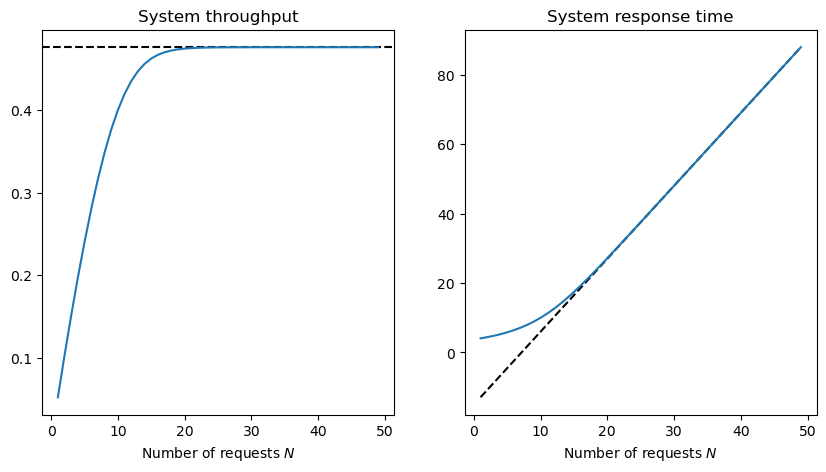

In [37]:
Dmax = np.max(S*V) # max of the service demands
Ns = range(1,50)
Xsys = np.zeros_like(Ns, dtype=float)
Rsys = np.zeros_like(Ns, dtype=float)
for i,N in enumerate(Ns):
    _, R, _, _ = mva(N, V, S, Z, delay)
    Rsys[i] = np.dot(V, R)
    Xsys[i] = N/(Z+Rsys[i])
plt.subplots(1, 2, figsize=(10,5))
plt.subplot(1,2,1)
plt.axhline(y = 1/Dmax, c='k', linestyle='--') # upper bound on X
plt.plot(Ns, Xsys)
plt.title(f"System throughput")
plt.xlabel(f"Number of requests $N$")
plt.subplot(1,2,2)
plt.plot(Ns, Ns*Dmax - Z, c='k', linestyle='--') # lower bound on R
plt.plot(Ns, Rsys)
plt.title("System response time")
plt.xlabel(f"Number of requests $N$")
plt.show();

The bottleneck is the device with maximum service demand.

In [15]:
D = S*V
print(D)
print(np.argmax(D))

[0.605 2.1   1.35 ]
1


In the example above, device 1 is the bottleneck. The system throughput increases only if the bottleneck is improved.

💡 **Q**: Change the service time one at a time, and observe the impact on the system throughput.